### Homework 9 ###

In [141]:
import matplotlib.pyplot as plt
import numpy as np
from qiskit_nature.second_q.drivers import PySCFDriver
from qiskit_nature.units import DistanceUnit
from qiskit_nature.second_q.mappers import JordanWignerMapper
from qiskit_algorithms import VQE
from qiskit_algorithms.optimizers import SLSQP
from qiskit.circuit.library import n_local
from qiskit.primitives import StatevectorEstimator

In [9]:
driver = PySCFDriver(
    atom= "H 0 0 0; H 0 0 0.735",
    basis = "sto3g",
    unit = DistanceUnit.ANGSTROM
)

In [10]:
problem = driver.run()

In [15]:
# --- Molecular Data Dashboard ---
# This cell extracts all the key physical and chemical properties stored in 'problem'
print("=== H2 MOLECULE SUMMARY ===")

# 1. Basisc Electronic Structure
# num_particles returns (alpha_electrons, beta_electrons)
alpha_e, beta_e = problem.num_particles
print(f"Total Electrons: {sum(problem.num_particles)} ({alpha_e} up, {beta_e} down)")
print(f"Spatial Orbitals: {problem.num_spatial_orbitals} (Physical 'slots' for electrons)")
print(f"Spin Orbitals: {problem.num_spin_orbitals} (Total quantum states available)")

# 2. Energy Reference Points (In Hartree units)
# The Hartree-Fock energy is the best 'classical' guess for the ground state
print(f"\n--- Energy Benchmarks (Hartree) ---")
print(f"Nuclear Repulsion:      {problem.nuclear_repulsion_energy:.5f}")
print(f"Harttree-Fock Energy:   {problem.reference_energy:.5f}")

# 3. Orbital Energies
# These are the energy levels of the individual molecular orbitals
print(f"\n---Orbital Energy Levels ---")
for i, energy in enumerate(problem.orbital_energies):
    status = "Occupied" if i < alpha_e else "Empty"
    print(f"Orbital {i}: {energy:10.5f} Ha [{status}]")

# 4. Symmetry & Geometry
print(f"\n--- Geometry Info ---")
# The 'molecule' attribute contains the raw coordinats and atoms
mol = problem.molecule
print(f"Atoms: {mol.symbols}")
# Calculate bond length (distance between the two H atoms)
coords = np.array(mol.coords)
dist = np.linalg.norm(coords[0] - coords[1])
print(f"Bond Length: {dist:.4f} Bohr")
# 1 \AA ~ 1.8897 Bohr
print("===========================")

=== H2 MOLECULE SUMMARY ===
Total Electrons: 2 (1 up, 1 down)
Spatial Orbitals: 2 (Physical 'slots' for electrons)
Spin Orbitals: 4 (Total quantum states available)

--- Energy Benchmarks (Hartree) ---
Nuclear Repulsion:      0.71997
Harttree-Fock Energy:   -1.11700

---Orbital Energy Levels ---
Orbital 0:   -0.58063 Ha [Occupied]
Orbital 1:    0.67634 Ha [Empty]

--- Geometry Info ---
Atoms: ['H', 'H']
Bond Length: 1.3889 Bohr


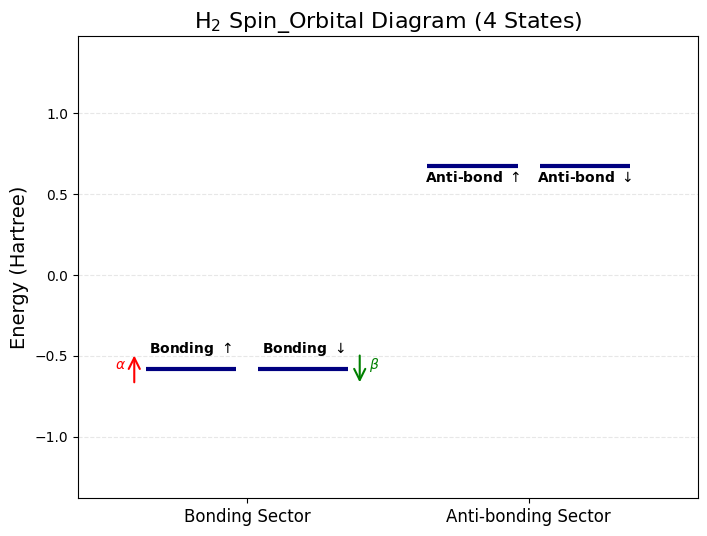

In [122]:
spatial_energies = problem.orbital_energies

spin_energies = [spatial_energies[0], spatial_energies[0], spatial_energies[1], spatial_energies[1]]

spin_labels = [r'\text{Bonding} \uparrow', r'\text{Bonding} \downarrow', r'\text{Anti-bond} \uparrow', r'\text{Anti-bond} \downarrow']
spin_labels = [ r'Bonding $\uparrow$', r'Bonding $\downarrow$', r'Anti-bond $\uparrow$', r'Anti-bond $\downarrow$']
plt.figure(figsize=(8,6))
x_positions = [0.2, 0.4, 0.7, 0.9]
for i in range(4):
    plt.hlines(spin_energies[i], x_positions[i]-0.08, x_positions[i]+0.08, lw=3, color = 'navy')
    plt.text(x_positions[i], spin_energies[i] - ((x_positions[i] - 0.5)/abs(x_positions[i] - 0.5))*0.1, spin_labels[i], ha='center', fontsize=10, fontweight='bold')

plt.annotate('', xy = (x_positions[0]-.1, spin_energies[0] + 0.1), xytext=(x_positions[0]-.1, spin_energies[0]-0.1), arrowprops=dict(arrowstyle='->', lw=1.5, color='red', mutation_scale=20))
plt.text(x_positions[0]-.125, spin_energies[0], r"$\alpha$", ha='center', fontsize=10, fontweight='bold', color = "red")
plt.annotate('', xy = (x_positions[1]+.1, spin_energies[1] - 0.1), xytext=(x_positions[1]+.1, spin_energies[1] + 0.1), arrowprops=dict(arrowstyle='->', lw=1.5, color='green', mutation_scale=20))
plt.text(x_positions[1]+.125, spin_energies[1], r"$\beta$", ha='center', fontsize=10, fontweight='bold', color = "green")

plt.title(r"H$_2$ Spin_Orbital Diagram (4 States)", fontsize = 16)
plt.ylabel("Energy (Hartree)", fontsize=14)
plt.xticks([0.3,0.8], ["Bonding Sector", "Anti-bonding Sector"], fontsize=12)
plt.xlim(0, 1.1)
plt.ylim(min(spin_energies)-0.8, max(spin_energies)+0.8)
plt.grid(axis = 'y', linestyle='--', alpha=0.3)

plt.show()

In [ ]:
# 1. Choose a Translation Strategy:
# Computers use qubits (0 and 1), but chemistry uses fermions (electrons).
# The JordanWignerMapper is the standard 'dictonary' used to translate
# electron behaviors into quantum gate instructions.
mapper = JordanWignerMapper()

# 2. Grab the Chemistry Math:
# We pull the 'Hamiltonian' (the mathematical desctiption of the
# molecule's energy) from the 'problem' object we created earlier.
hamiltonian  = problem.hamiltonian

# 3. Translate to Qubits:
# We take the complex second-quantized (chemical) math and 'map' it
# into a qubit operator (a list of Pauli strings like XIIZ, ZIZI, etc.)
# This is what the quantum computer actually runs.
qubit_op = mapper.map(hamiltonian.second_q_op())

# 4. Check the result:
print(f"Number of qubits needed: {qubit_op.num_qubits}")

print(qubit_op)
print(hamiltonian)
qubit_op.

Number of qubits needed: 4
SparsePauliOp(['IIII', 'IIIZ', 'IIZI', 'IZII', 'ZIII', 'IIZZ', 'IZIZ', 'ZIIZ', 'YYYY', 'XXYY', 'YYXX', 'XXXX', 'IZZI', 'ZIZI', 'ZZII'],
              coeffs=[-0.81054798+0.j,  0.17218393+0.j, -0.22575349+0.j,  0.17218393+0.j,
 -0.22575349+0.j,  0.12091263+0.j,  0.16892754+0.j,  0.16614543+0.j,
  0.0452328 +0.j,  0.0452328 +0.j,  0.0452328 +0.j,  0.0452328 +0.j,
  0.16614543+0.j,  0.17464343+0.j,  0.12091263+0.j])


In [140]:
# --- Qubit Hamiltonian Dashboard ---
print("=== QIBIT OPERATOR (MACHINE CODE) SUMMARY ===")

# 1. Basic Stats
num_qubits = qubit_op.num_qubits
num_terms = len(qubit_op)
print(f"Number of Qubits:       {num_qubits}")
print(f"Total Pauli Terms:      {num_terms}")
print("-" * 45)

# 2. Breaking down the Pauli Strings
# We sort them by the absolute value of the coefficient to see the most
# 'important' terms first
sorted_terms = sorted(qubit_op.to_list(), key = lambda x: abs(x[1]), reverse=True)

print(f"{'Paulit String':<15} | {'Cofficient (Energy Contribution)':<30}")
print("-" * 45)

# Display the first 10 terms (the most significant ones)
for pauli_str, coeff in sorted_terms[:10]:
    # coeff is often a complex number, we take the real part for energy
    real_coeff = coeff.real
    print(f"{pauli_str:<15} | {real_coeff:>10.5f} Ha")

if num_terms > 10:
    print(f"... and {num_terms - 10} more terms.")

# 3. Physical Interpretation for Beginners
print("-" * 45)
print("NTPRRETATION:")
print(f"- 'IIII' is a constant energy offset.")
print(f"- 'Z' terms (like ZIII) represent orbital energy (On-site).")
print(f"- 'ZZ' terms (like ZZII) represent electron repulsion (Coulomb).")
print(f"- 'XXXX' or 'YYYY' terms represent electron hopping/exchange.")
print("=" * 45)


=== QIBIT OPERATOR (MACHINE CODE) SUMMARY ===
Number of Qubits:       4
Total Pauli Terms:      15
---------------------------------------------
Paulit String   | Cofficient (Energy Contribution)
---------------------------------------------
IIII            |   -0.81055 Ha
ZIII            |   -0.22575 Ha
IIZI            |   -0.22575 Ha
ZIZI            |    0.17464 Ha
IIIZ            |    0.17218 Ha
IZII            |    0.17218 Ha
IZIZ            |    0.16893 Ha
ZIIZ            |    0.16615 Ha
IZZI            |    0.16615 Ha
IIZZ            |    0.12091 Ha
... and 5 more terms.
---------------------------------------------
NTPRRETATION:
- 'IIII' is a constant energy offset.
- 'Z' terms (like ZIII) represent orbital energy (On-site).
- 'ZZ' terms (like ZZII) represent electron repulsion (Coulomb).
- 'XXXX' or 'YYYY' terms represent electron hopping/exchange.


In [146]:
ansatz = n_local(
    num_qubits = 4,
    rotation_blocks=["ry", "rz"],
    entanglement_blocks='cz',
    entanglement='linear',
    reps=3,
    insert_barriers=True
)

optimizer = SLSQP(maxiter=100)
estimator = StatevectorEstimator()
vqe = VQE(
    estimator=estimator,
    ansatz=ansatz,
    optimizer=optimizer
)

In [148]:
result = vqe.compute_minimum_eigenvalue(qubit_op)
energy = result.eigenvalue.real + problem.nuclear_repulsion_energy
print(energy)

-1.137287382154438


In [160]:
from qiskit_algorithms import NumPyMinimumEigensolver
exact = NumPyMinimumEigensolver()
exact_result = exact.compute_minimum_eigenvalue(qubit_op)
energy_exact = exact_result.eigenvalue.real + problem.nuclear_repulsion_energy
print(energy_exact)
print ( exact_result )

-1.137306035753399
{   'aux_operators_evaluated': None,
    'eigenstate': Statevector([-2.11301241e-30-1.91255686e-32j,
              6.68816321e-17+5.78343595e-17j,
              6.11482291e-17+1.27645918e-17j,
             -2.69717843e-17-2.53190717e-17j,
             -1.15589883e-17-1.76734915e-17j,
              4.95913007e-01-8.61179438e-01j,
             -2.33970475e-18-6.02172110e-17j,
             -9.52252084e-17-1.94879410e-17j,
             -1.19476351e-17-6.91698945e-18j,
             -6.82403716e-17+6.19043403e-17j,
             -5.56594152e-02+9.66555489e-02j,
              7.15367809e-17+1.89310088e-16j,
             -1.72355092e-17+3.26192586e-18j,
              3.51777074e-17-9.03126520e-18j,
              5.10650662e-17-1.24019858e-16j,
             -3.49993885e-16-2.52162790e-16j],
            dims=(2, 2, 2, 2)),
    'eigenvalue': np.float64(-1.8572750302023786)}


#### Exercises
- Which part is quantum?
    - The estimator and ansatz are the quantum parts. The ansatz is a basline quess based off of a trial wavefunction and the quantum system. The estimator simulates a quantum computer to evaluate the Hamiltonian
- Which part is classical
    - The optimizer is the clasical part. It uses a classsical optimizer to find the best values for the given inputs, guiding the quantum circuit.
- What limits today's quantum computers?
    - The main limitations of todays quantum computers is noise and error in quantum states due to enviornment and gate noise
- Compare with exact solver:
    - The energy is close but the exact result did get slightly smaller. The main difference was speed, the exact solver ran almost instantly while the the vqe took 13 seconds.